**History & Evolution of ML**

- Traditional Software Engineering: Explicit Rules Combined with Data to Produce Output

- In the Real World: Predicting Academic Outcomes, Detecting Financial Fraud, Detecting Identity Fraud

*With Traditional Programming -> Data + Handwritten Rules -> Output*

- Machine Learning: Data + Known Ouputs -> Learned Rules

In [1]:
import os
from IPython.display import Image

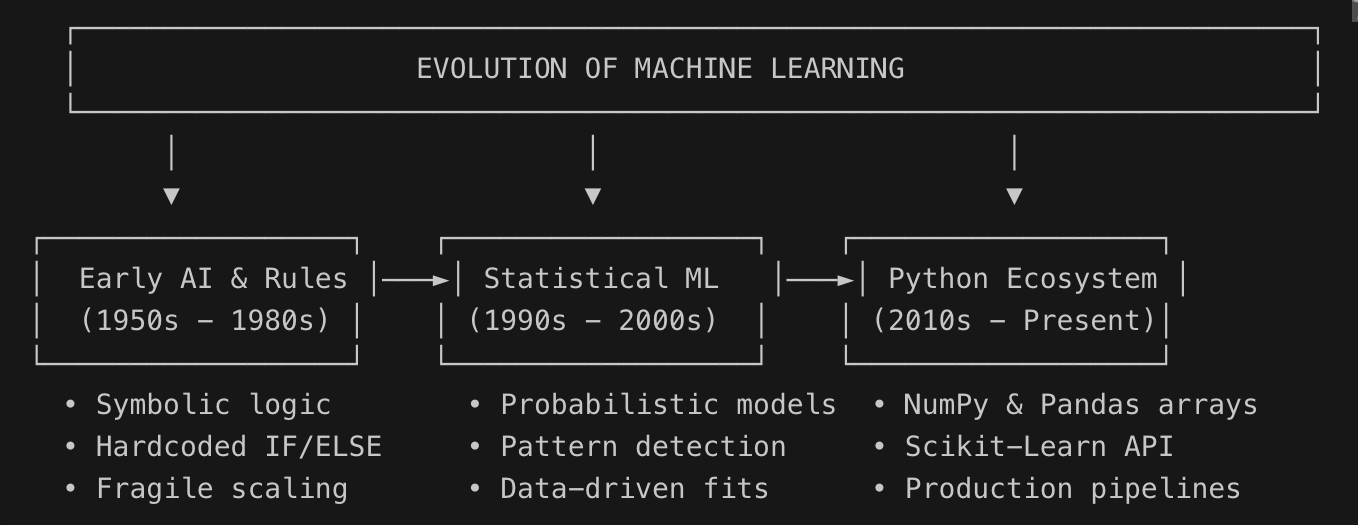

In [2]:
img_evolution = 'Evolution of ML.jpeg' if os.path.exists('Evolution of ML.jpeg') else '/content/drive/MyDrive/Data/Evolution of ML.jpeg'
Image(filename=img_evolution)

**The Python Ecosystem**

- Rich Ecosystem of Third Party Libraries

- NumPy & Pandas

- Matplotlib

- Scikit-Learn

**Machine Learning in the Data Science Workflow**

- Data Science: It exists in the intersection of hacking skills(programming), math, statistical knowledge, and enterprise domain knowledge.

- Machine Learning: It serves as the computational engine for pattern detection and predictive inference.

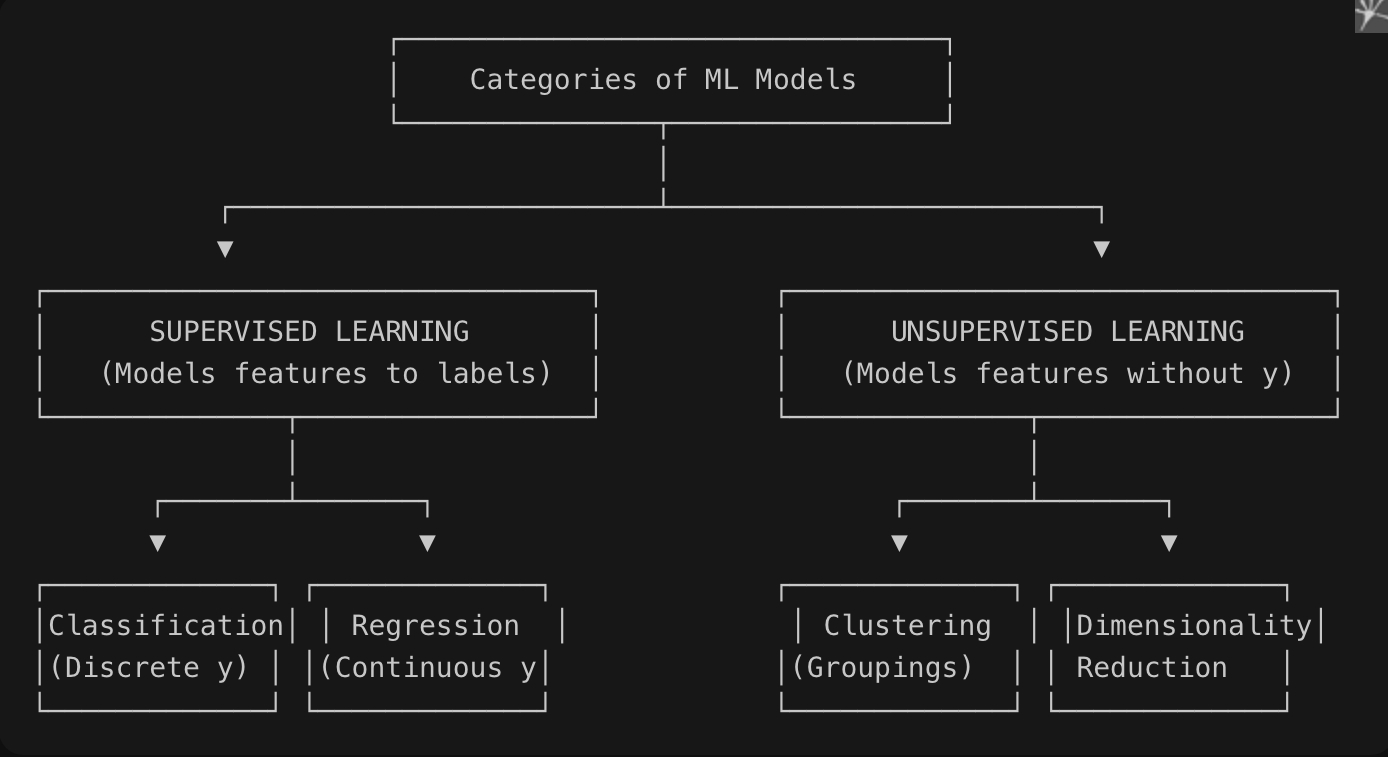

In [3]:
img_categories = 'Categories of ML Models.jpeg' if os.path.exists('Categories of ML Models.jpeg') else '/content/drive/MyDrive/Data/Categories of ML Models.jpeg'
Image(filename=img_categories)

**Scikit-Learn Data Representation & The Estimator API**

- Two Components of tabular data: Scikit-Learn

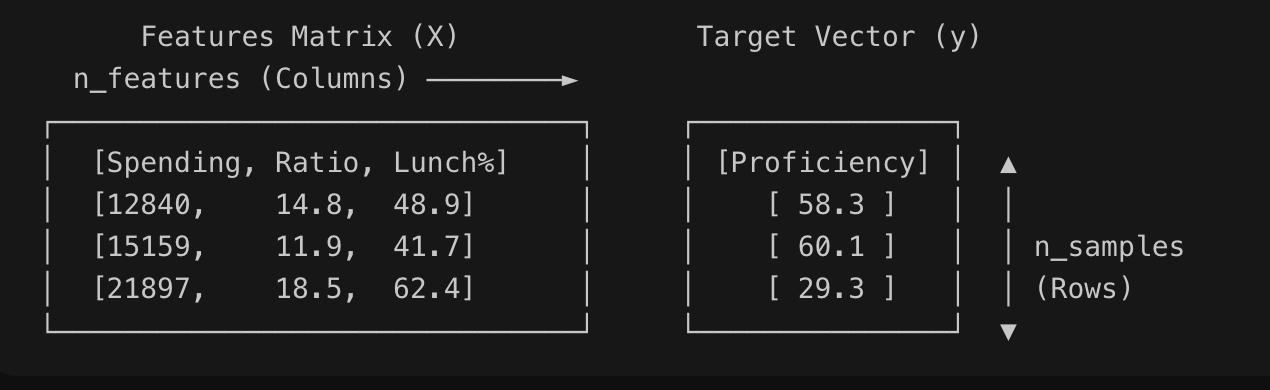

In [4]:
img_feature_target = 'Feature and Target.jpeg' if os.path.exists('Feature and Target.jpeg') else '/content/drive/MyDrive/Data/Feature and Target.jpeg'
Image(filename=img_feature_target)

**The 5-Step Scikit-Learn Estimator Workflow**

1. Choose a model class

2. Choose Hyperparameters

3. Format Data

4. Fit the model

5. Apply the model

**Real-World Case Study: Education Performance Prediction**

- Build an ML Pipeline using Institutional Records from the US Educational System Dataset

In [7]:
# Environment Setup
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set the visualization aesthetics
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("muted")

In [10]:
# Load Dataset into a DataFrame
perf_list= ['institution_name', 'level',
            'control', 'title_i_status',
            'per_pupil_expenditure_usd',
            'student_teacher_ratio',
            'percent_free_reduced_lunch',
            'math_proficiency_pct']

In [9]:
# DataFrame (supports local repo & Google Colab)
pd.options.display.max_columns = None
pd.options.display.max_rows = None
data_path = 'us_education_system_dataset.csv' if os.path.exists('us_education_system_dataset.csv') else '/content/drive/MyDrive/Data/us_education_system_dataset.csv'
us_edu_data = pd.read_csv(data_path)
us_edu_data.head()

,institution_id,institution_name,state_code,state_name,county,nces_locale,level,control,title_i_status,total_enrollment,number_of_teachers,student_teacher_ratio,percent_free_reduced_lunch,racial_white_pct,racial_black_pct,racial_hispanic_pct,racial_asian_pct,racial_native_pct,racial_two_or_more_pct,special_education_pct,english_learner_pct,per_pupil_expenditure_usd,federal_funding_pct,state_funding_pct,local_funding_pct,math_proficiency_pct,reading_proficiency_pct,graduation_rate_pct,chronic_absenteeism_pct,avg_sat_score,avg_act_score,ap_ib_participation_pct,postsecondary_enrollment_pct,stem_certified_flag,broadband_access_pct
0,US-EDU-10001,Jefferson Elementary School,MA,Massachusetts,Central County,Suburban - Midsize,Elementary School,Public,Title I Schoolwide,447,30,14.8,48.9,70.9,2.4,15.4,8.1,0.1,3.1,14.4,12.9,12840,15.0,54.8,30.2,58.3,58.1,80.9,18.0,NaN,NaN,NaN,NaN,No,91.6
1,US-EDU-10002,Lakeshore Middle School,FL,Florida,Miami-Dade County,Suburban - Midsize,Middle School,Private Religious,Not Applicable,293,29,10.0,1.2,34.7,8.6,36.1,13.3,1.3,6.0,13.7,19.3,17009,0.0,2.0,98.0,84.8,98.0,93.5,17.8,NaN,NaN,NaN,NaN,No,94.4
2,US-EDU-10003,Meadowbrook Elementary Academy,TX,Texas,Bexar County,City - Large,Elementary School,Private For-Profit,Not Applicable,315,17,18.2,36.0,26.2,29.2,22.9,12.3,1.9,7.5,15.7,11.3,15374,10.7,55.5,33.8,54.6,66.2,80.2,19.5,NaN,NaN,NaN,NaN,No,94.0
3,US-EDU-10004,Roosevelt Primary School,FL,Florida,Palm Beach County,Suburban - Large,Elementary School,Public,Not Title I Eligible,389,34,11.3,15.1,49.2,16.7,4.3,26.4,0.1,3.3,13.8,9.8,17065,6.8,38.3,54.9,66.1,70.5,82.1,20.5,NaN,NaN,NaN,NaN,No,96.4
4,US-EDU-10005,Highland Park Primary School,MI,Michigan,Macomb County,Suburban - Large,Elementary School,Public,Title I Targeted,397,29,13.9,45.6,78.1,3.2,8.0,3.9,2.1,4.7,19.8,5.3,16823,15.0,42.3,42.7,54.6,46.7,90.2,19.9,NaN,NaN,NaN,NaN,No,86.3


In [11]:
# Performance Feature Data
perf_data = us_edu_data[perf_list]

In [12]:
perf_data.head()

,institution_name,level,control,title_i_status,per_pupil_expenditure_usd,student_teacher_ratio,percent_free_reduced_lunch,math_proficiency_pct
0,Jefferson Elementary School,Elementary School,Public,Title I Schoolwide,12840,14.8,48.9,58.3
1,Lakeshore Middle School,Middle School,Private Religious,Not Applicable,17009,10.0,1.2,84.8
2,Meadowbrook Elementary Academy,Elementary School,Private For-Profit,Not Applicable,15374,18.2,36.0,54.6
3,Roosevelt Primary School,Elementary School,Public,Not Title I Eligible,17065,11.3,15.1,66.1
4,Highland Park Primary School,Elementary School,Public,Title I Targeted,16823,13.9,45.6,54.6


**Feature Processing & Engineering**

In [13]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

In [14]:
# Select our raw input predictors and our target
numeric_features = ['per_pupil_expenditure_usd', 'student_teacher_ratio', 'percent_free_reduced_lunch']
categorical_features = ['title_i_status', 'control']
target_col = 'math_proficiency_pct'

In [15]:
# Drop Missing target Labels
perf_data_clean = perf_data.dropna(subset=[target_col]).copy()

In [16]:
perf_data_clean.head()

,institution_name,level,control,title_i_status,per_pupil_expenditure_usd,student_teacher_ratio,percent_free_reduced_lunch,math_proficiency_pct
0,Jefferson Elementary School,Elementary School,Public,Title I Schoolwide,12840,14.8,48.9,58.3
1,Lakeshore Middle School,Middle School,Private Religious,Not Applicable,17009,10.0,1.2,84.8
2,Meadowbrook Elementary Academy,Elementary School,Private For-Profit,Not Applicable,15374,18.2,36.0,54.6
3,Roosevelt Primary School,Elementary School,Public,Not Title I Eligible,17065,11.3,15.1,66.1
4,Highland Park Primary School,Elementary School,Public,Title I Targeted,16823,13.9,45.6,54.6


---
## 📌 Session 3 Key Takeaways: Foundations of the Scikit-Learn ML Pipeline

1. **Paradigm Shift (Rules $\rightarrow$ Learned Representations):** Unlike traditional software engineering (`Data + Handwritten Rules -> Output`), Machine Learning infers generalizable mathematical mappings directly from historical observations (`Data + Known Outputs -> Learned Rules`).
2. **Model Taxonomy Alignment:** Selecting the right algorithm starts with diagnosing whether the problem has labeled supervision (`Supervised`: discrete `Classification` vs. continuous `Regression`) or seeks latent structure (`Unsupervised`: `Clustering` vs. `Dimensionality Reduction`).
3. **Strict $X$ and $y$ Separation:** Separating predictors (`numeric_features = ['per_pupil_expenditure_usd', 'student_teacher_ratio', 'percent_free_reduced_lunch']` and `categorical_features = ['title_i_status', 'control']`) from `target_col = 'math_proficiency_pct'` and dropping missing target labels (`dropna(subset=[target_col])`) prepares clean, leakage-free inputs for `SimpleImputer` and `OneHotEncoder` transformers.